# 02 · RFM segmentation (fixed)

**Question:** which customers matter most, and what should we do with each group?

RFM = **R**ecency (days since last order), **F**requency (number of orders), **M**onetary (total revenue). Each is scored 1–4, where 4 is best.

In [1]:
import sys
from pathlib import Path

# make the src/ package importable from notebooks/ (no hard-coded C:\ paths)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}" if abs(v) < 1 else f"{v:,.2f}")

from autosales.data import load_raw, build_order_lines, build_order_summary, build_customer_features
from autosales import kpis, segmentation, clustering, modelling, plots
%matplotlib inline

In [2]:
lines = build_order_lines(load_raw())
orders = build_order_summary(lines)
cust = build_customer_features(lines, orders)
cust[["customer_name", "recency_days", "frequency", "monetary", "avg_order_value", "fulfilment_experience"]].sort_values("monetary", ascending=False).head()

,customer_name,recency_days,frequency,monetary,avg_order_value,fulfilment_experience
32,Euro Shopping Channel,1,26,"912,294.11","35,088.24",Order at risk / lost
53,Mini Gifts Distributors Ltd.,3,17,"654,858.06","38,521.06",Clean record
6,"Australian Collectors, Co.",185,5,"200,995.41","40,199.08",Clean record
55,Muscle Machine Inc,183,4,"197,736.94","49,434.24",Clean record
43,La Rochelle Gifts,1,4,"180,124.90","45,031.22",Clean record


## 1. The v1 bug
v1 ranked frequency and monetary with `ascending=False` (so the biggest customer gets rank 1) and *then* labelled the quartiles `[1, 2, 3, 4]`. Together that gives the **biggest customers the lowest score**:

In [3]:
cust["v1_value_tier"] = segmentation.legacy_v1_value_tier(cust)
cust.groupby("v1_value_tier").monetary.agg(["count", "mean", "sum"]).reindex(["High Value", "Mid Value", "Low Value"])

,count,mean,sum
v1_value_tier,,,
High Value,27,"62,322.64","1,682,711.39"
Mid Value,51,"125,831.43","6,417,402.84"
Low Value,11,"150,918.86","1,660,107.48"


Under v1, "Low Value" customers averaged **£151k** each and "High Value" customers **£62k**. That's backwards. Euro Shopping Channel, the top customer with 26 orders, was labelled Low Value.

## 2. The fix
- Score from the **percentile rank**, with higher always better (recency is negated first).
- `method="average"` so customers with the same value always get the same score. v1's `method="first"` split ties arbitrarily by row order.

In [4]:
import inspect
print(inspect.getsource(segmentation.quartile_score))

def quartile_score(values: pd.Series, higher_is_better: bool = True) -> pd.Series:
    """Score 1 (worst) .. 4 (best) from percentile rank.

    Uses method="average" so customers with the same value always get the
    same score (v1 used method="first", which broke ties arbitrarily by row
    order). With heavy ties (many customers have exactly 3 orders) some
    scores can end up empty - that is a property of the data, not a bug.
    """
    ranked = values if higher_is_better else -values
    pct = ranked.rank(pct=True, method="average")
    return np.clip(np.ceil(pct * 4), 1, 4).astype(int)



In [5]:
rfm = segmentation.add_rfm(cust)
rfm[["customer_name", "recency_days", "frequency", "monetary", "R_score", "F_score", "M_score", "RFM_score", "value_tier", "rfm_segment"]].sort_values("monetary", ascending=False).head(8)

,customer_name,recency_days,frequency,monetary,R_score,F_score,M_score,RFM_score,value_tier,rfm_segment
32,Euro Shopping Channel,1,26,"912,294.11",4,4,4,12,High Value,Champions
53,Mini Gifts Distributors Ltd.,3,17,"654,858.06",4,4,4,12,High Value,Champions
6,"Australian Collectors, Co.",185,5,"200,995.41",3,4,4,11,High Value,Champions
55,Muscle Machine Inc,183,4,"197,736.94",3,4,4,11,High Value,Champions
43,La Rochelle Gifts,1,4,"180,124.90",4,4,4,12,High Value,Champions
30,"Dragon Souveniers, Ltd.",91,5,"172,989.68",3,4,4,11,High Value,Champions
44,Land of Toys Inc.,199,4,"164,069.44",2,4,4,10,High Value,At Risk – High Value
78,The Sharp Gifts Warehouse,40,4,"160,010.27",4,4,4,12,High Value,Champions


### Sanity checks: scores must move in the right direction

In [6]:
pd.DataFrame({
    "avg revenue by M_score": rfm.groupby("M_score").monetary.mean(),
    "avg recency by R_score": rfm.groupby("R_score").recency_days.mean(),
})

,avg revenue by M_score,avg recency by R_score
1,"47,808.68",352.77
2,"78,564.55",207.45
3,"103,190.84",136.68
4,"204,774.44",32.26


In [7]:
rfm.groupby("frequency").F_score.unique().to_frame("F_score for that order count")

,F_score for that order count
frequency,
1,[1]
2,[1]
3,[3]
4,[4]
5,[4]
17,[4]
26,[4]


Many customers have exactly 3 orders. Because ties share a score, no customer lands on F = 2. That's an honest property of the data, not a bug.

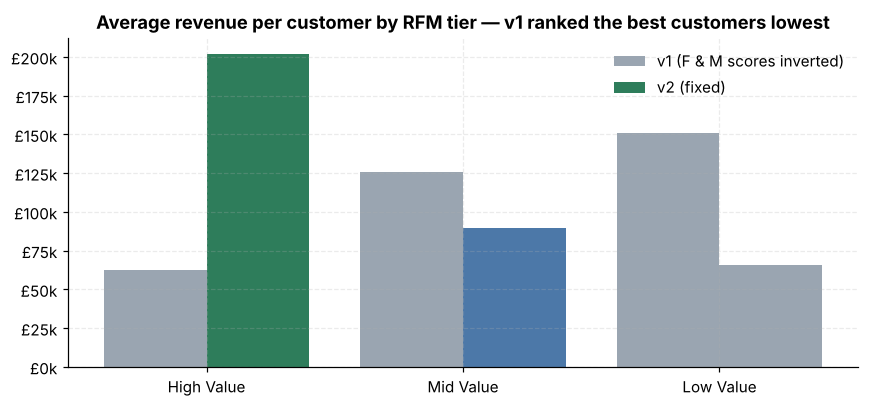

In [8]:
_ = plots.rfm_fix(rfm)

## 3. Value tiers and revenue concentration

In [9]:
tiers = rfm.groupby("value_tier").agg(customers=("customer_name", "count"), revenue=("monetary", "sum"), avg_revenue=("monetary", "mean"), median_recency=("recency_days", "median"))
tiers["revenue_share"] = tiers.revenue / tiers.revenue.sum()
tiers.reindex(["High Value", "Mid Value", "Low Value"])

,customers,revenue,avg_revenue,median_recency,revenue_share
value_tier,,,,,
High Value,22,"4,447,446.15","202,156.64",43.50,0.4557
Mid Value,38,"3,407,993.52","89,684.04",163.50,0.3492
Low Value,29,"1,904,782.04","65,682.14",265.00,0.1952


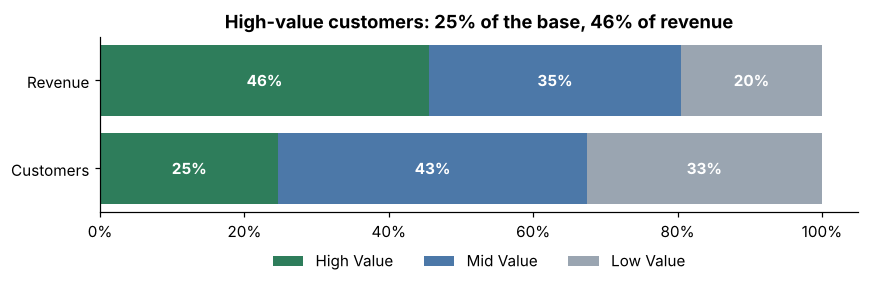

In [10]:
_ = plots.tier_share(rfm)

## 4. Actionable RFM segments
Value tiers rank customers; segments say what to *do*. We use the classic R × FM grid:

In [11]:
seg = rfm.groupby("rfm_segment").agg(customers=("customer_name", "count"), revenue=("monetary", "sum"), median_recency=("recency_days", "median"), median_orders=("frequency", "median"))
seg["revenue_share"] = seg.revenue / seg.revenue.sum()
seg["action"] = seg.index.map(segmentation.SEGMENT_ACTIONS)
seg.sort_values("revenue", ascending=False)

,customers,revenue,median_recency,median_orders,revenue_share,action
rfm_segment,,,,,,
Champions,28,"5,014,199.94",59.00,4.00,0.5137,"Protect: account management, priority fulfilme..."
Hibernating,31,"2,135,541.91",260.00,2.00,0.2188,Low-cost reactivation (email / catalogue); do ...
At Risk – High Value,13,"1,523,434.41",209.00,3.00,0.1561,Win back: proactive outreach before they lapse...
Potential Loyalists,17,"1,087,045.45",83.00,3.00,0.1114,Grow: cross-sell adjacent product lines to rai...


## 5. Value × fulfilment experience
Fulfilment experience is now based on **events** (did the customer have an order at risk or lost?) rather than v1's arbitrary % thresholds.

In [12]:
pd.crosstab(rfm.value_tier, rfm.fulfilment_experience, margins=True).reindex(["High Value", "Mid Value", "Low Value", "All"])

fulfilment_experience,Clean record,Issue resolved,Order at risk / lost,All
value_tier,,,,
High Value,16,0,6,22
Mid Value,32,2,4,38
Low Value,29,0,0,29
All,77,2,10,89


In [13]:
rfm[rfm.fulfilment_experience == "Order at risk / lost"][["customer_name", "country", "value_tier", "rfm_segment", "monetary", "at_risk_orders", "lost_orders"]].sort_values("monetary", ascending=False)

,customer_name,country,value_tier,rfm_segment,monetary,at_risk_orders,lost_orders
32,Euro Shopping Channel,Spain,High Value,Champions,"912,294.11",1,1
44,Land of Toys Inc.,USA,High Value,At Risk – High Value,"164,069.44",0,1
78,The Sharp Gifts Warehouse,USA,High Value,Champions,"160,010.27",1,0
26,Danish Wholesale Imports,Denmark,High Value,Champions,"145,041.60",1,0
69,Scandinavian Gift Ideas,Sweden,High Value,Champions,"134,259.33",0,1
83,"UK Collectables, Ltd.",UK,High Value,Champions,"118,008.27",0,1
77,Tekni Collectables Inc.,USA,Mid Value,Potential Loyalists,"83,228.19",1,0
36,Gifts4AllAges.com,USA,Mid Value,Potential Loyalists,"83,209.88",1,0
86,"Volvo Model Replicas, Co",Sweden,Mid Value,At Risk – High Value,"75,754.88",1,0
5,"Australian Collectables, Ltd",Australia,Mid Value,Potential Loyalists,"64,591.46",1,0


**Takeaways**
- High-value customers are 25% of the base and bring in 46% of revenue.
- 13 high-value customers have gone quiet ("At Risk – High Value"). That's the clearest win-back list.
- 10 customers have an order currently at risk or lost. The high-value ones among them are the priority for service recovery.